In [1]:
import tensorflow as tf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D
from tensorflow.keras.layers import Flatten, Dense

In [2]:
train_data = pd.read_csv(r'D:\Downloads\LP IV Updated Datasets\LP IV Updated Datasets\FNN and CNN\HandWritten MNIST\mnist_train.csv')
test_data = pd.read_csv(r'D:\Downloads\LP IV Updated Datasets\LP IV Updated Datasets\FNN and CNN\HandWritten MNIST\mnist_test.csv')

In [3]:
X_train = train_data.drop('label', axis=1).values
y_train = train_data['label'].values

X_test = test_data.drop('label', axis=1).values
y_test = test_data['label'].values

In [4]:
X_train = X_train / 255.0
X_test = X_test / 255.0

In [5]:
X_train = X_train.reshape(-1, 28, 28, 1)
X_test = X_test.reshape(-1, 28, 28, 1)

In [6]:
print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (60000, 28, 28, 1)
Testing data: (10000, 28, 28, 1)


In [11]:
model = Sequential([
    tf.keras.layers.Input(shape=(28,28,1)),
    Conv2D(32, (3,3), activation='relu'),
    MaxPooling2D((2,2)),
    Conv2D(64, (3,3), activation='relu'),
    MaxPooling2D((2,2)),

    Flatten(),

    Dense(128, activation='relu'),
    Dense(10, activation='softmax')
])

In [13]:
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

In [14]:
history = model.fit(
    X_train, y_train,
    epochs=10,
    batch_size=64,
    validation_split=0.1
)

Epoch 1/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 67s 74ms/step - accuracy: 0.9486 - loss: 0.1685 - val_accuracy: 0.9850 - val_loss: 0.0553
Epoch 2/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 41s 49ms/step - accuracy: 0.9844 - loss: 0.0504 - val_accuracy: 0.9872 - val_loss: 0.0455
Epoch 3/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 32s 38ms/step - accuracy: 0.9893 - loss: 0.0329 - val_accuracy: 0.9872 - val_loss: 0.0452
Epoch 4/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 41s 49ms/step - accuracy: 0.9922 - loss: 0.0249 - val_accuracy: 0.9902 - val_loss: 0.0369
Epoch 5/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 31s 37ms/step - accuracy: 0.9936 - loss: 0.0189 - val_accuracy: 0.9898 - val_loss: 0.0473
Epoch 6/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 34s 41ms/step - accuracy: 0.9954 - loss: 0.0146 - val_accuracy: 0.9905 - val_loss: 0.0359
Epoch 7/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 47s 56ms/step - accuracy: 0.9961 - loss: 0.0116 - val_accuracy: 0.9913 - val_loss: 0.0371
Epoch 8/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 32s 38ms/step - accuracy: 0.9959 - loss: 0.0110 - 

In [15]:
loss, accuracy = model.evaluate(X_test, y_test)

print('Test Loss: ', loss)
print('Test Accuracy: ', accuracy)

313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - accuracy: 0.9925 - loss: 0.0312
Test Loss:  0.03124159201979637
Test Accuracy:  0.9925000071525574


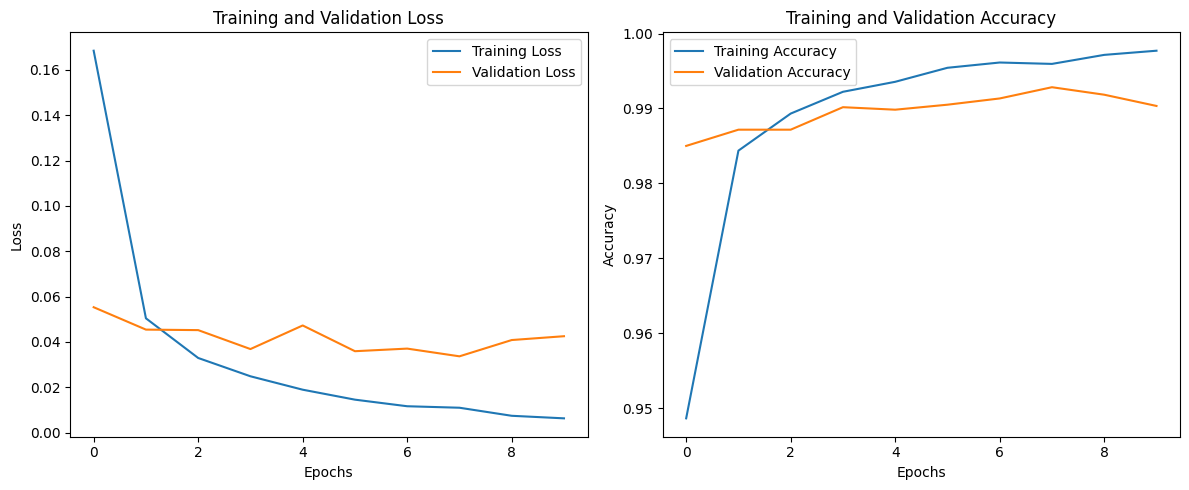

In [16]:
# Plot training loss and accuracy
plt.figure(figsize=(12, 5))

# Training and validation loss
plt.subplot(1, 2, 1)
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Training and Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()

# Training and validation accuracy
plt.subplot(1, 2, 2)
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Training and Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()

plt.tight_layout()
plt.show()

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step


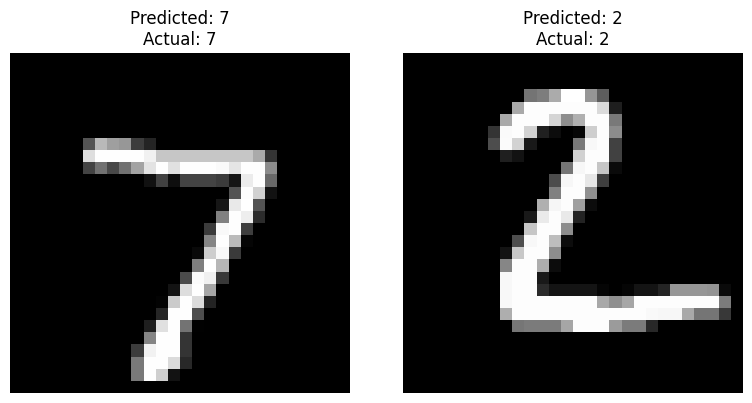

In [17]:
# Display 2 sample predictions
predictions = model.predict(X_test)
predicted_labels = predictions.argmax(axis=1)

plt.figure(figsize=(8, 4))

for i in range(2):
    plt.subplot(1, 2, i+1)

    plt.imshow(X_test[i].reshape(28, 28), cmap='gray')

    plt.title("Predicted: " + str(predicted_labels[i]) +
              "\nActual: " + str(y_test[i]))

    plt.axis('off')

plt.tight_layout()
plt.show()